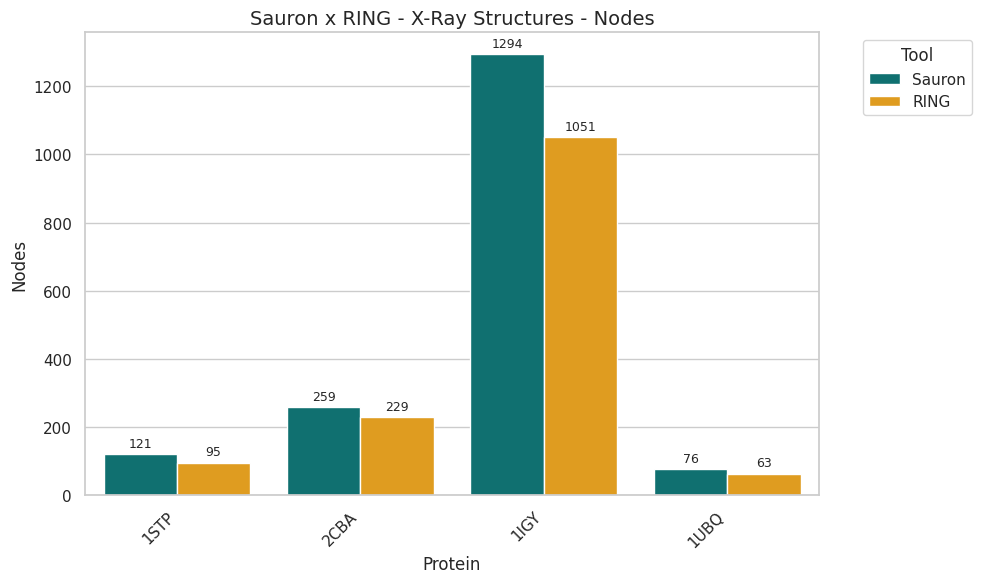

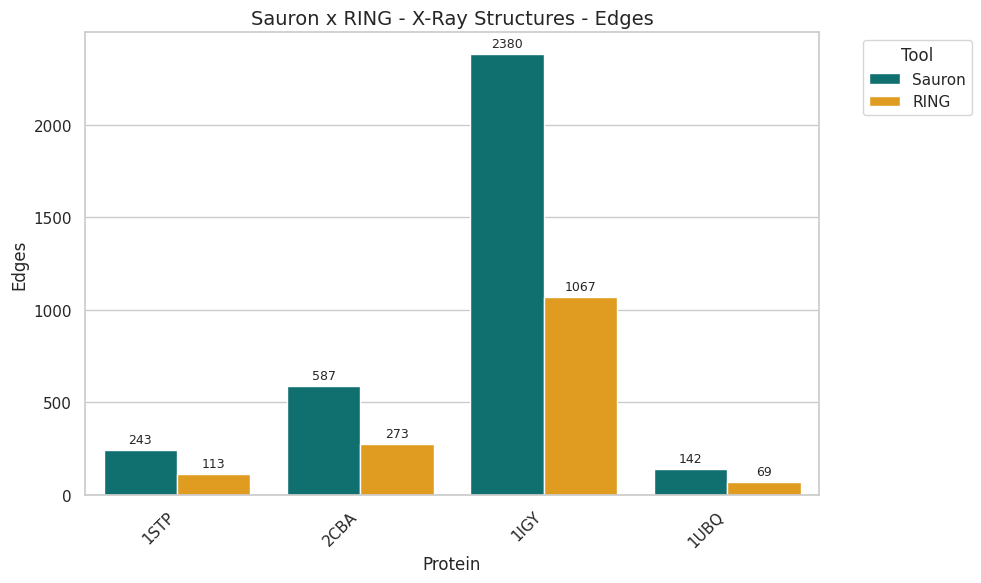

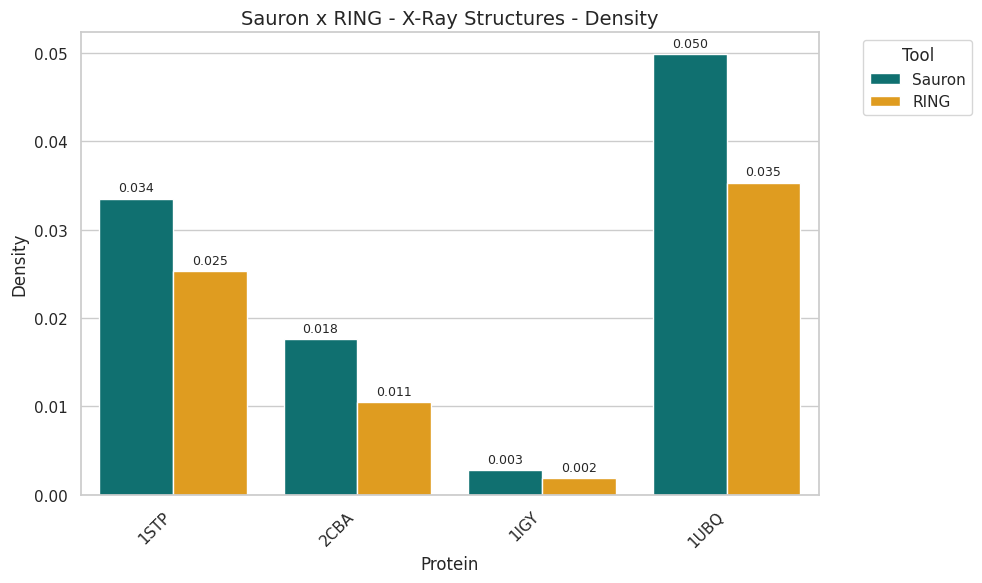

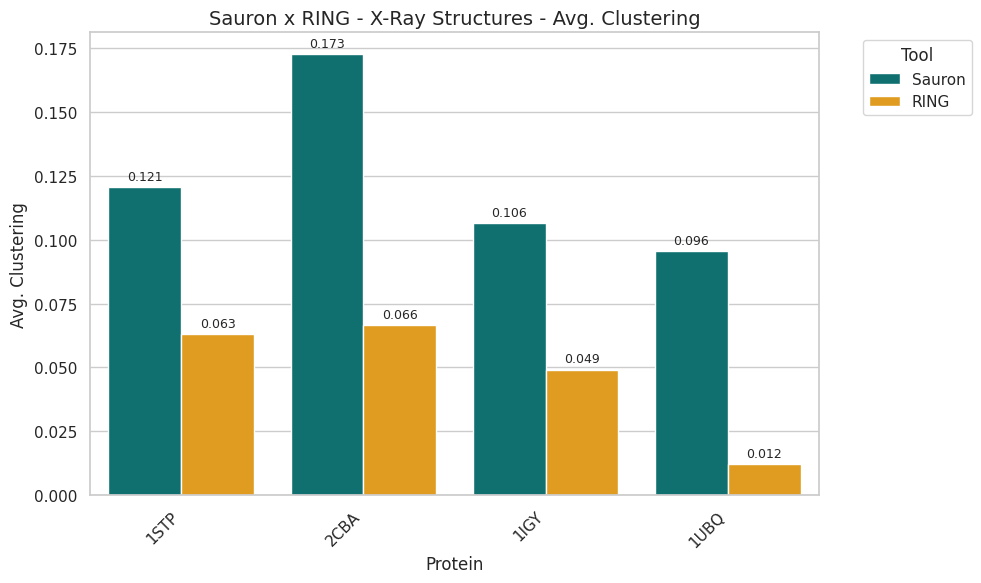

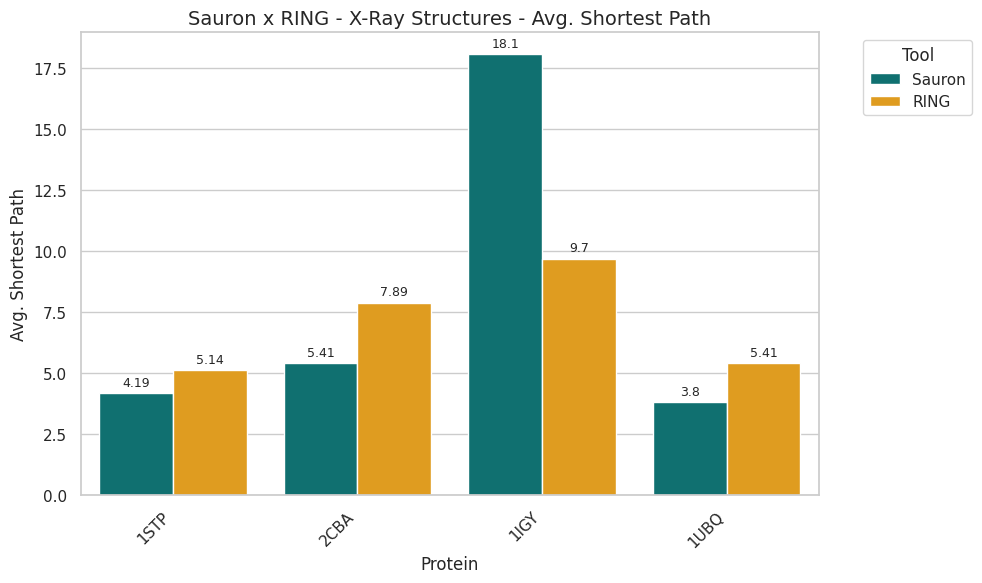

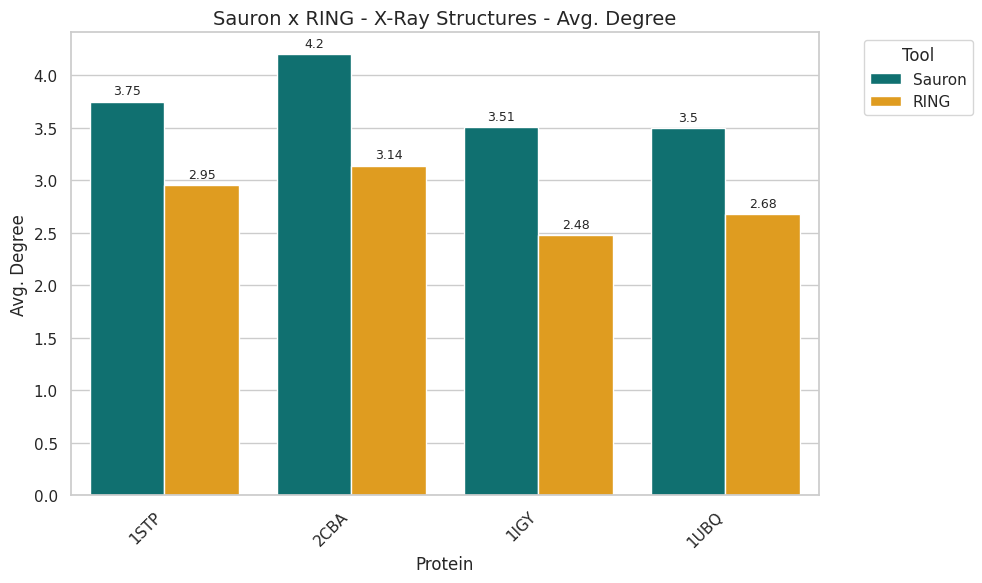

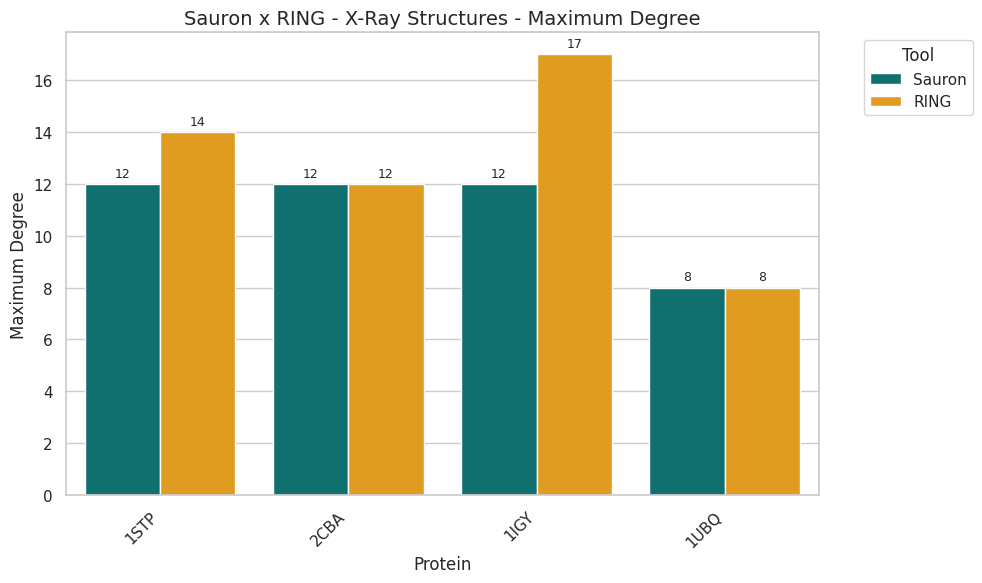

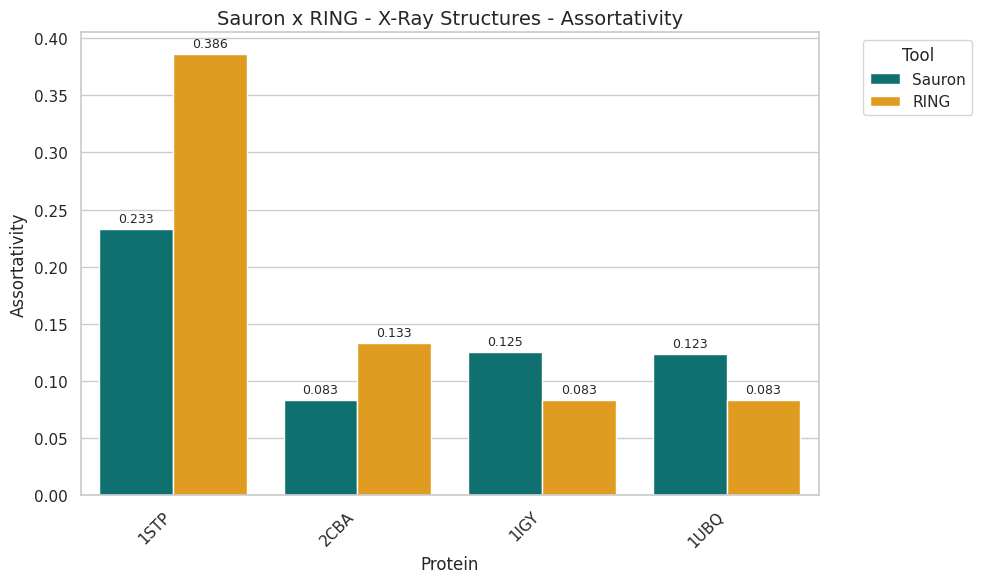

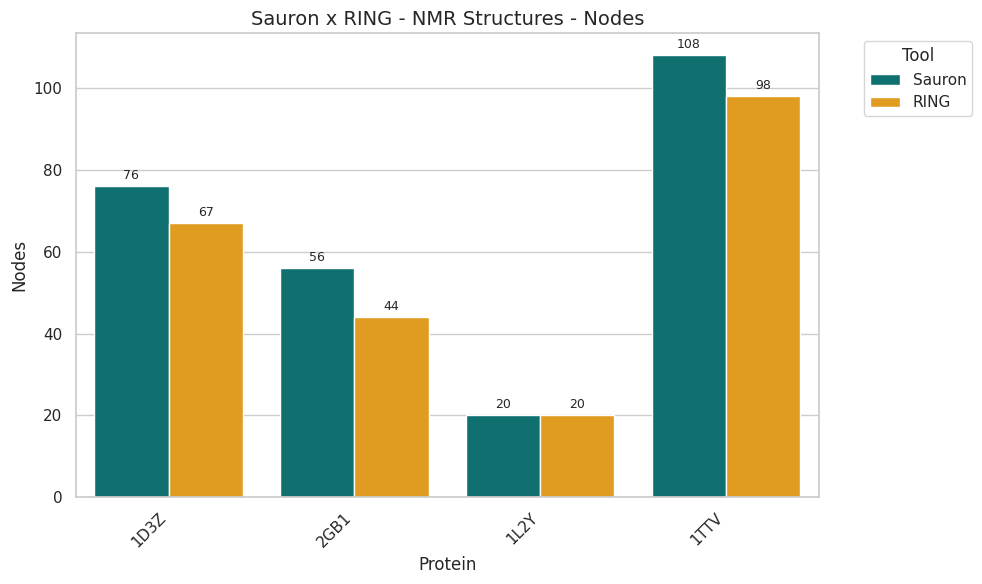

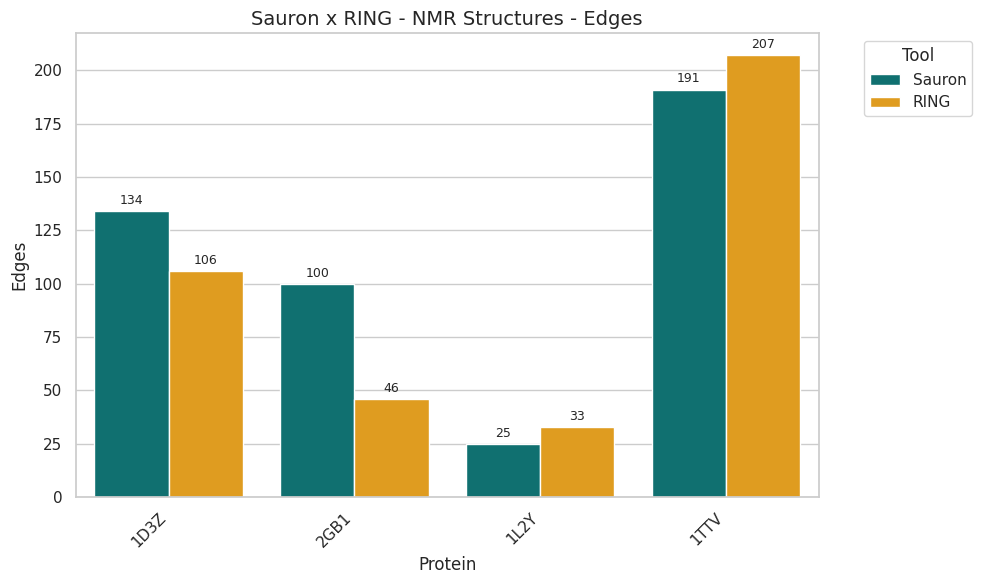

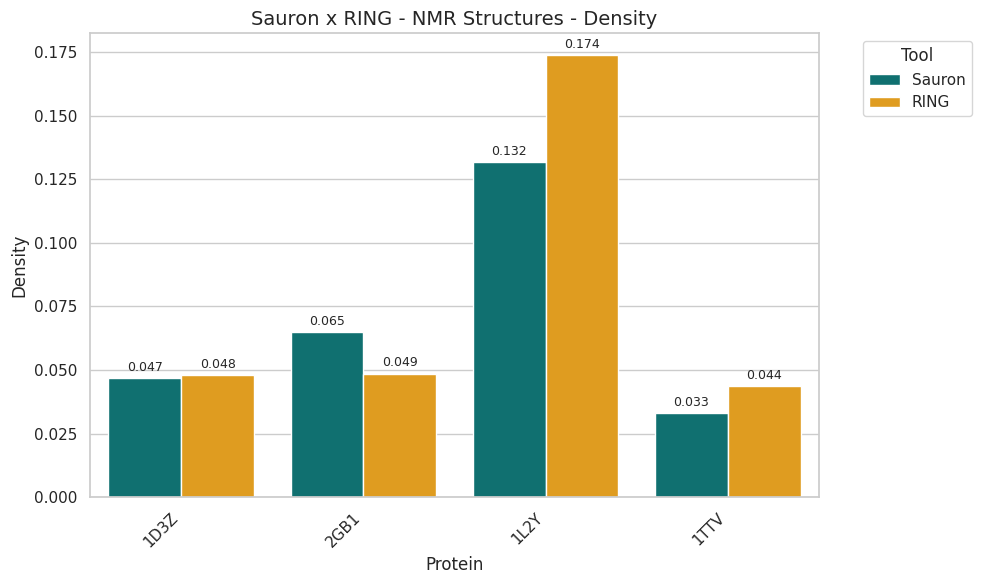

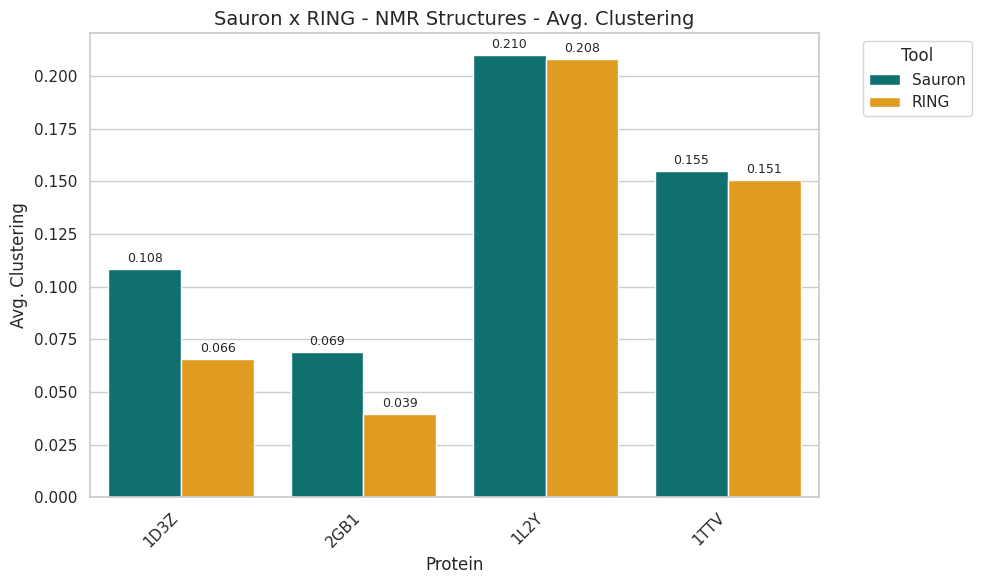

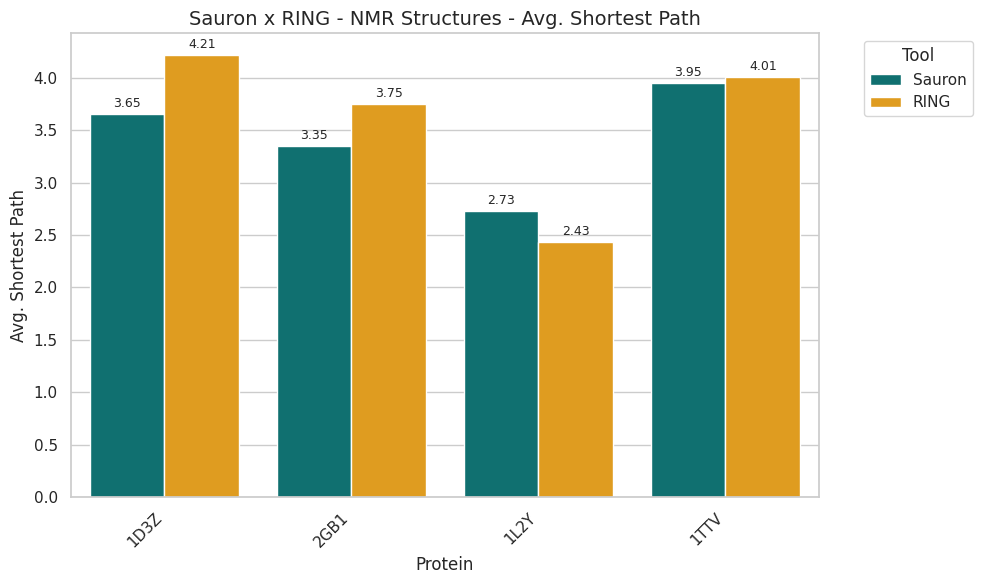

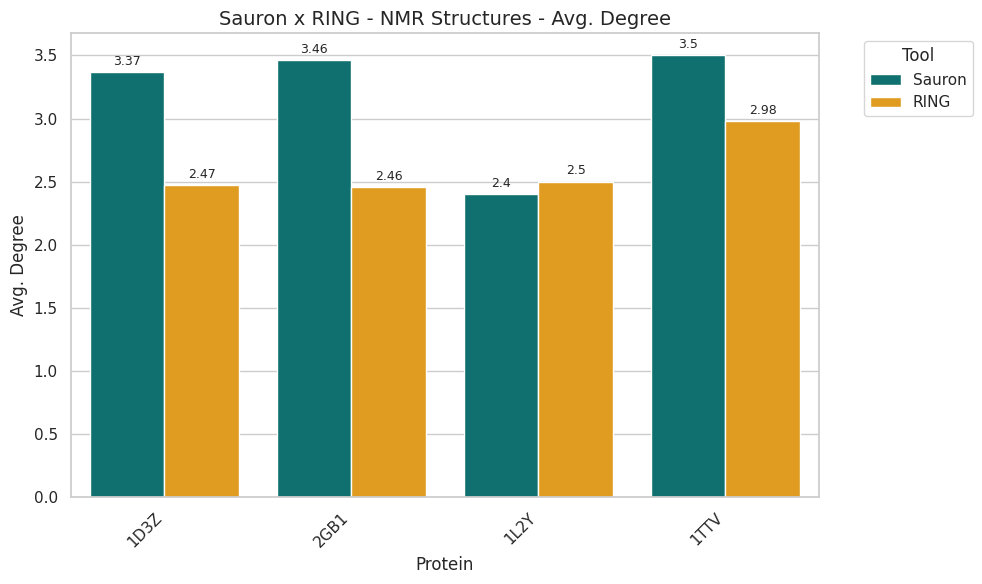

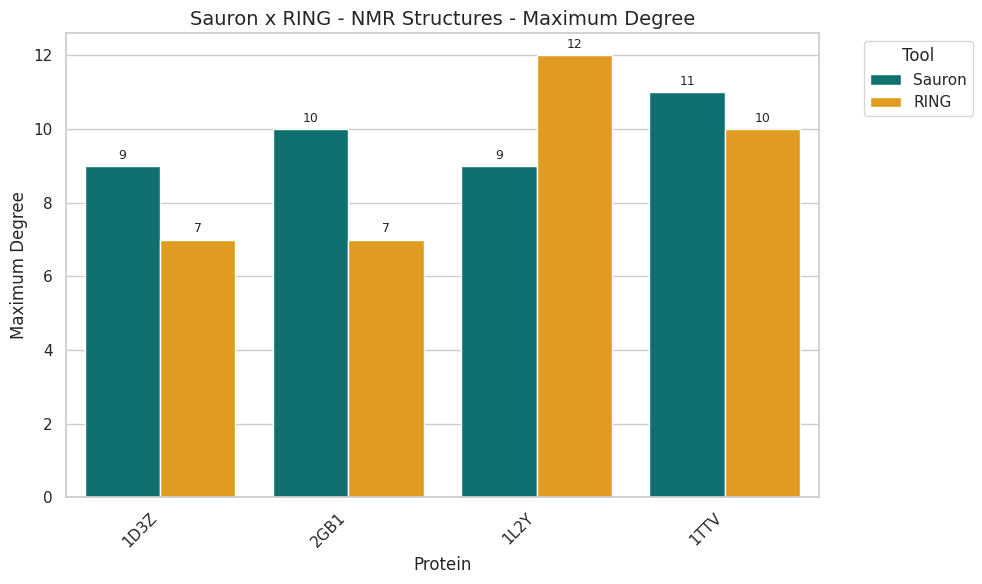

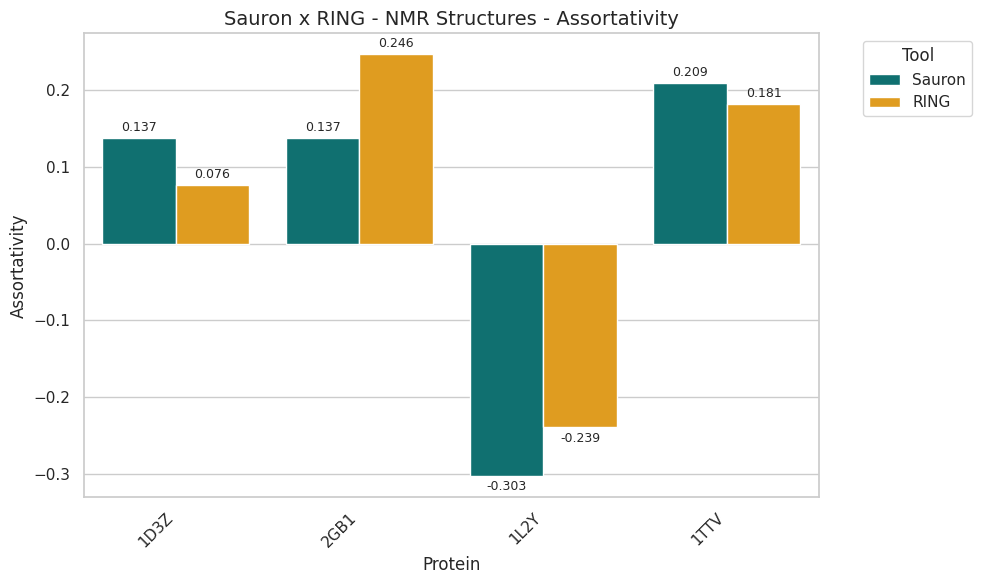

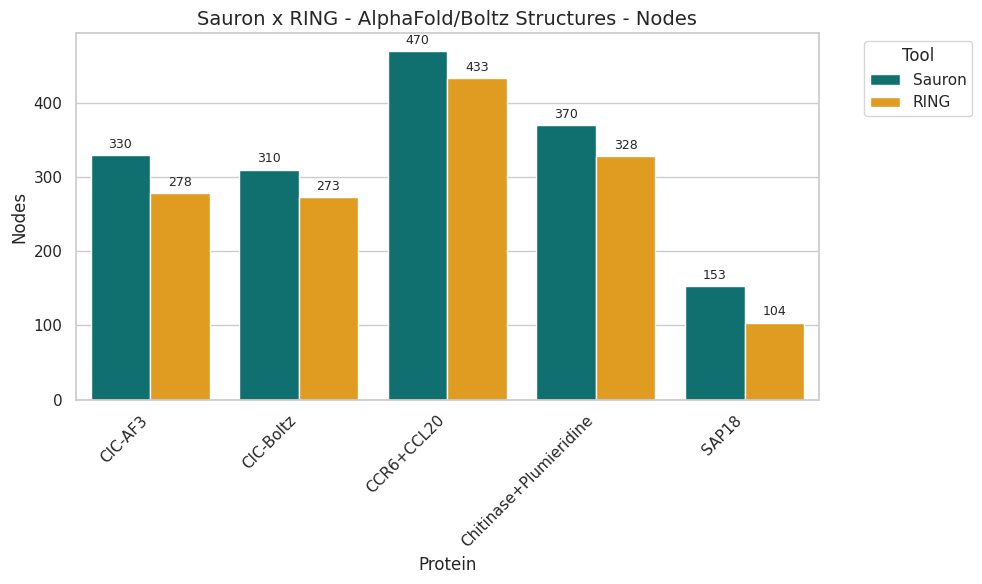

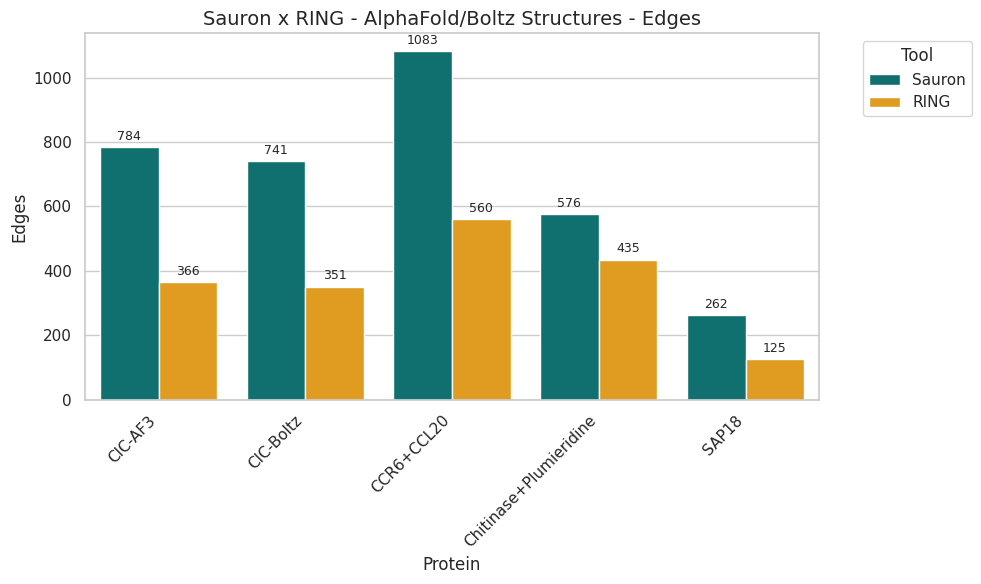

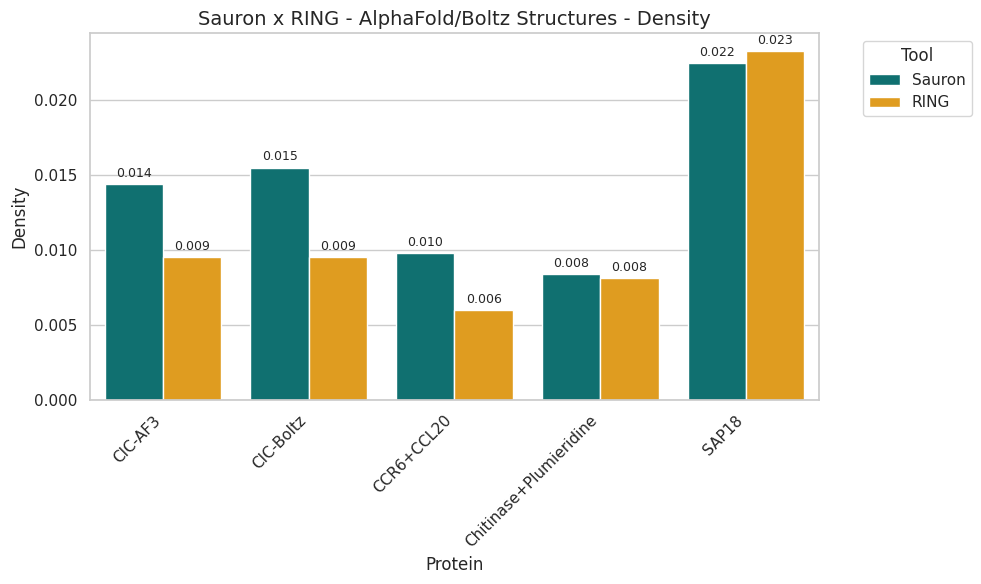

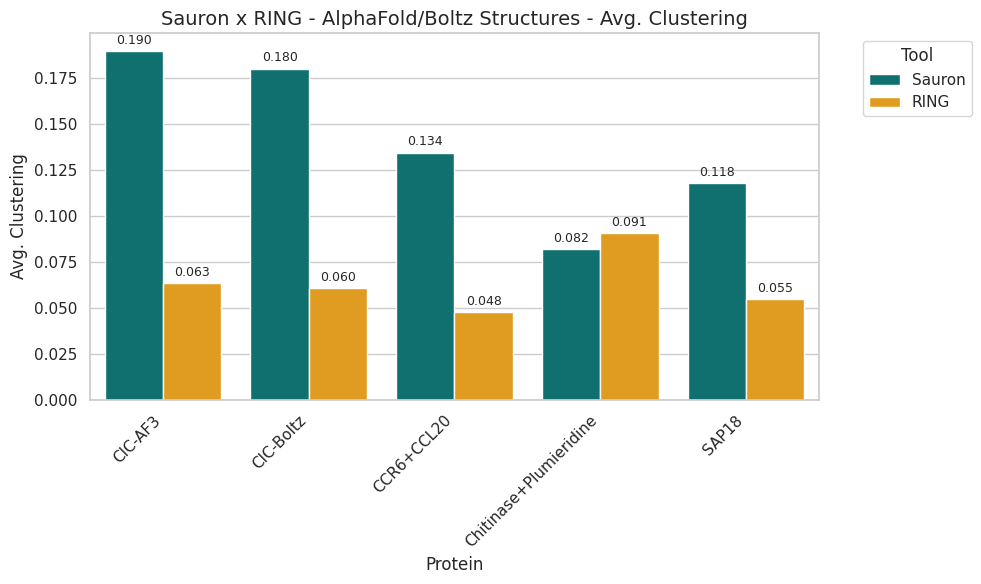

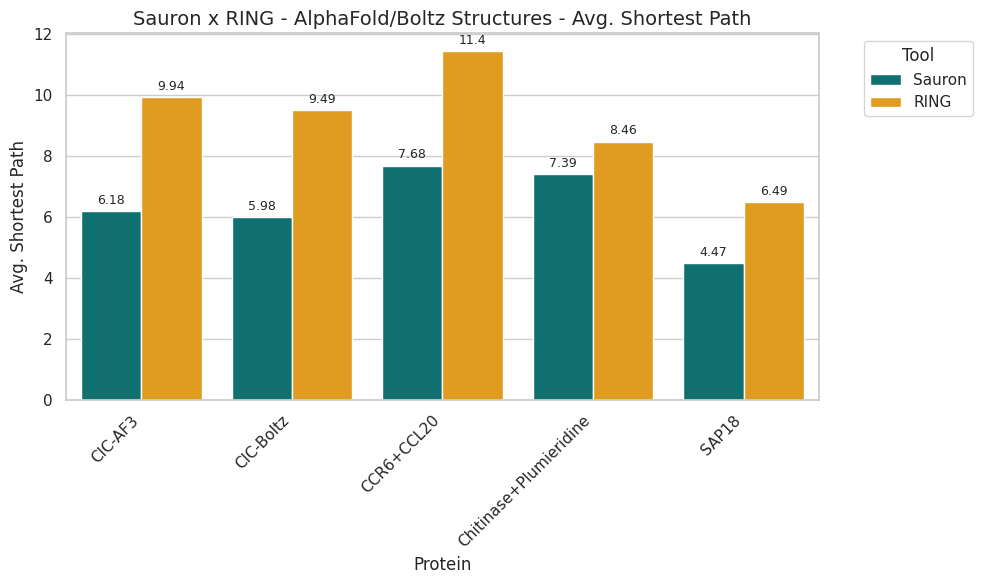

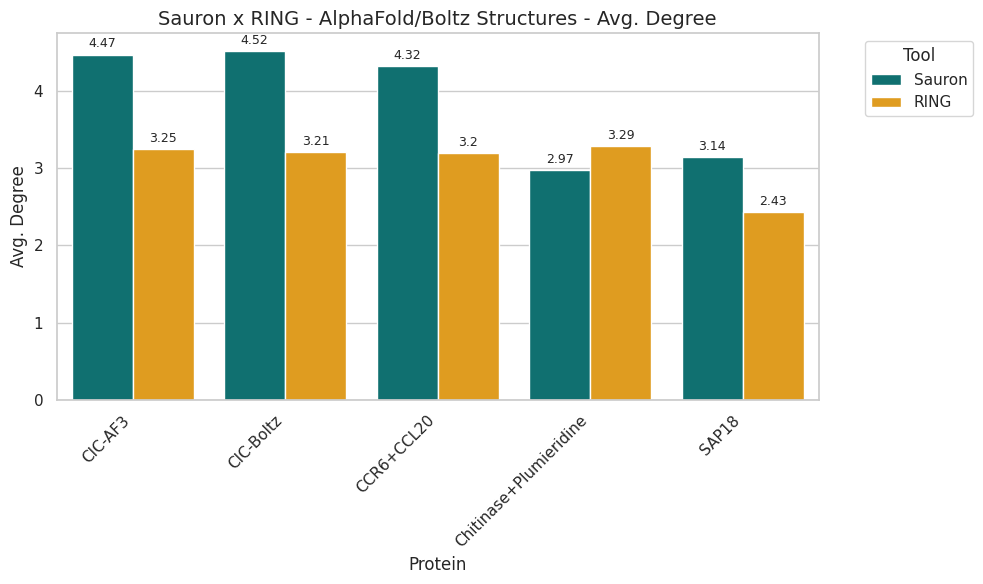

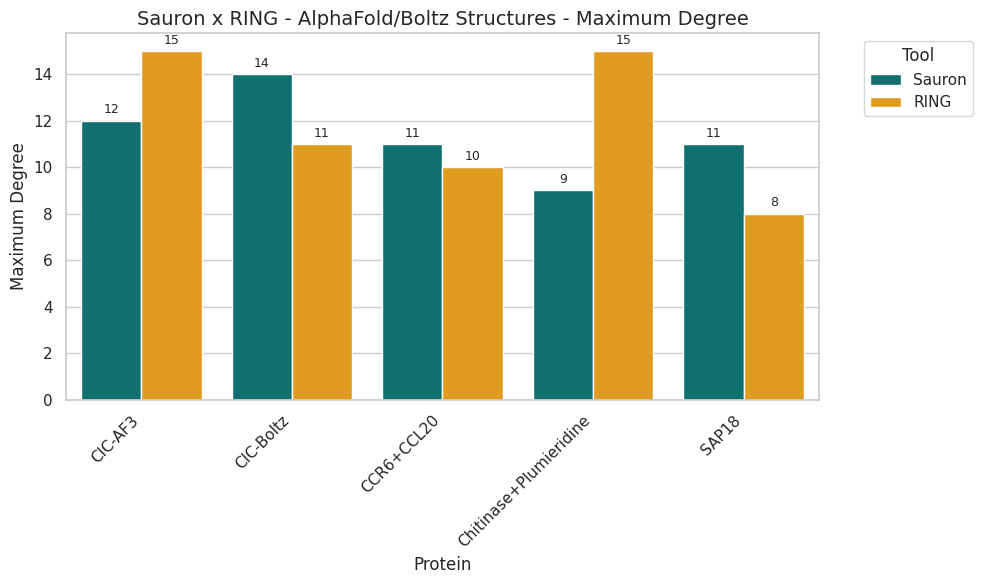

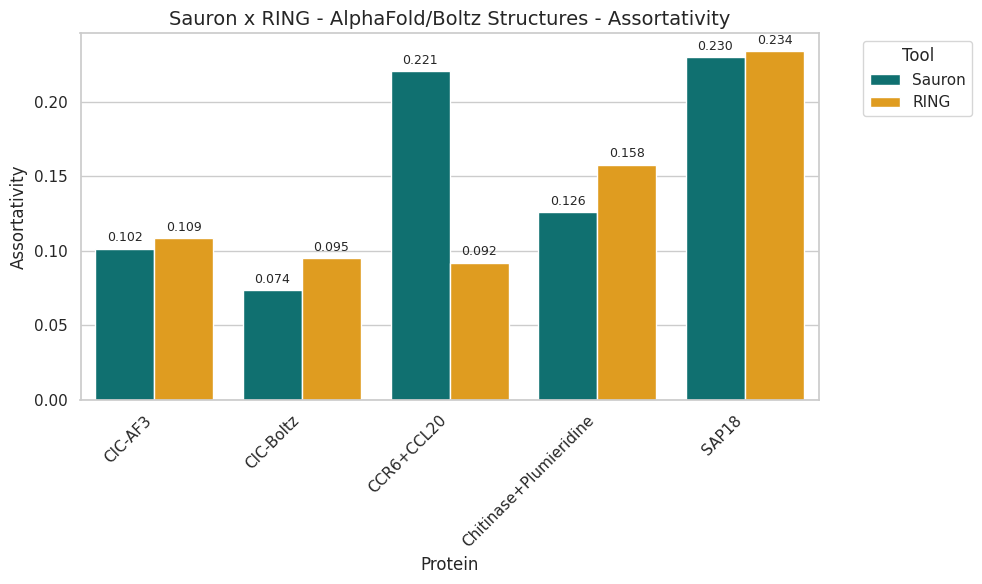

In [10]:
# upload the benchmarking_data file in the session storage

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

csv_filename = 'benchmarking_data.csv'
df = pd.read_csv(csv_filename)

# Filter the dataframe to only include the tools 'Sauron' and 'RING' (case-sensitive)
df_filtered = df[df['Tool'].isin(['Sauron', 'RING'])].copy()

# Create a lowercase version of the protein names to ensure robust filtering
df_filtered['Protein_lower'] = df_filtered['Protein'].str.lower()

# Define the protein groups requested
protein_groups = {
    'Sauron x RING - X-Ray Structures': ['1ubq', '1igy', '2cba', '1stp'],
    'Sauron x RING - NMR Structures': ['1d3z', '1l2y', '2gb1', '1ttv'],
    'Sauron x RING - AlphaFold/Boltz Structures': ['chitinase+plumieridine', 'ccr6+ccl20', 'cic-af3', 'cic-boltz', 'sap18']
}

# List of metrics to plot
metrics = [
    'Nodes', 'Edges', 'Density', 'Avg. Clustering',
    'Avg. Shortest Path', 'Avg. Degree', 'Maximum Degree', 'Assortativity'
]

# Set the aesthetic style of the plots
sns.set_theme(style="whitegrid")

# Define custom colors
custom_palette = {'Sauron': 'teal', 'RING': 'orange'}

# Loop through each group and metric to create the grouped bar charts
for group_title, proteins in protein_groups.items():
    # Filter the data for the specific group
    df_group = df_filtered[df_filtered['Protein_lower'].isin(proteins)]

    if df_group.empty:
        print(f"No data found for group: {group_title}")
        continue

    for metric in metrics:
        plt.figure(figsize=(10, 6))

        # Create the grouped bar chart using seaborn
        ax = sns.barplot(
            data=df_group,
            x='Protein',
            y=metric,
            hue='Tool',
            palette=custom_palette
        )

        # Determine label format
        if metric in ['Nodes', 'Edges']:
            label_fmt = '%d'
        elif metric in ['Density', 'Avg. Clustering', 'Assortativity']:
            label_fmt = '%.3f'
        else:
            label_fmt = '%.3g'

        # Add the values on top of each bar
        for container in ax.containers:
            ax.bar_label(container, fmt=label_fmt, padding=3, fontsize=9)

        plt.title(f'{group_title} - {metric}', fontsize=14)
        plt.xlabel('Protein', fontsize=12)
        plt.ylabel(metric, fontsize=12)
        plt.xticks(rotation=45, ha='right')
        plt.legend(title='Tool', bbox_to_anchor=(1.05, 1), loc='upper left')
        plt.tight_layout()
        plt.show()
